## 1. 环境与依赖
使用已有 PyTorch 环境。需要 numpy、pandas、h5py、matplotlib、IPython；首次缺包时在该环境安装。下面只打印实际环境信息。

In [1]:
# 1. 环境
from __future__ import annotations
import copy, csv, hashlib, json, math, platform, random, time
from pathlib import Path
from dataclasses import dataclass, asdict
import h5py
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
font_set = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = next((x for x in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC'] if x in font_set),
    'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
print('Python:',
    platform.python_version(),
    'Torch:',
    torch.__version__,
    'CUDA:',
    torch.cuda.is_available())

Python: 3.9.13 Torch: 2.7.1+cu118 CUDA: True


## 2.可修改参数

先用 `quick` 检查本地流程，再改 `train`。单次固定一个 `SEED`；正式比较依次使用 42、43、44、45、46，所有方法同种子、同预算，不挑选最好一次。

默认：源训练 2/5/10/16/18，源验证 20；目标 14 的前 20 循环无标签适应，之后的后缀评估。目标前缀不读取 Y、T、hs。源域和目标域按发动机划分；这是**同一目标发动机前缀适应、后缀预测**，不是全新发动机的独立泛化测试。

窗口仍为 50 点、18 维 W+Xs，但为控制成本每循环稀疏抽端点。阶段标签采用过去高度变化率规则，不是已经验证准确的工况识别器。

In [2]:
# 'quick' / 'train' / 'full'；第一次建议自行改为quick检查环境
RUN_MODE = 'train'
DATA_PATH = 'E:/RUL/N-CMAPSS_DS02-006.h5'
# 输出到当前 notebook 工作目录下的 PCM_SSDA_results
RESULT_BASE = Path.cwd() / 'PCM_SSDA_full_results'

@dataclass
class Config:
    data: str = DATA_PATH
    train_units: tuple = (2, 5, 10, 16, 18)
    val_units: tuple = (20,)
    target: int = 14
    prefix_cycles: int = 20
    window: int = 50
    endpoints: int = 12
    fs_hz: float = 1.0
    phase_threshold: float = 0.5
    # 本实现预设30秒向后平均变化率；不是已验证最优值，也不是原文原样复现
    phase_lookback: int = 30
    particles: int = 256
    proxy_epochs: int = 60
    joint_epochs: int = 110
    patience: int = 12
    steps_per_epoch: int = 80
    batch: int = 128
    lr: float = 0.0003
    ssl_weight: float = 0.2
    domain_weight: float = 0.03
    phase_weight: float = 0.1
    covariance_shrink: float = 0.2
    likelihood_temperature: float = 1.0
    seed: int = 42
    device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
    mode: str = RUN_MODE

def config_for(seed):
    c = Config(seed=seed, data=DATA_PATH, mode=RUN_MODE)
    if RUN_MODE == 'quick':
        c.endpoints = 4
        c.particles = 48
        c.proxy_epochs = 3
        c.joint_epochs = 5
        c.steps_per_epoch = 8
        c.batch = 32
    if RUN_MODE not in ['quick', 'train', 'full']:
        raise ValueError('Unknown RUN_MODE')
    return c
SEED = 42
# True 时增加第二篇论文启发的软工况对齐
ENABLE_PHASE_EXTENSION = False
c = config_for(SEED)
assert Path(DATA_PATH).is_file(), f'请修改 DATA_PATH：{DATA_PATH}'
print(asdict(c))



print(f'当前模式={c.mode}；每个代理训练 {c.proxy_epochs} 轮；每个 RUL 模型最多 {c.joint_epochs} 轮、每轮 {c.steps_per_epoch} 步。')
print('完整流程：校准 → 七组 RUL 模型 → 统一测试 → 效果对照。')
print('下面先定义函数；执行第13/14节才开始读数据和校准训练。')
if c.mode == 'quick':
    print('当前是短程排错预算；不能用这些结果判断模型精度。正式实验请改为 train 后重启内核。')


{'data': 'E:/RUL/N-CMAPSS_DS02-006.h5', 'train_units': (2, 5, 10, 16, 18), 'val_units': (20,), 'target': 14, 'prefix_cycles': 20, 'window': 50, 'endpoints': 12, 'fs_hz': 1.0, 'phase_threshold': 0.5, 'phase_lookback': 30, 'particles': 256, 'proxy_epochs': 60, 'joint_epochs': 110, 'patience': 12, 'steps_per_epoch': 80, 'batch': 128, 'lr': 0.0003, 'ssl_weight': 0.2, 'domain_weight': 0.03, 'phase_weight': 0.1, 'covariance_shrink': 0.2, 'likelihood_temperature': 1.0, 'seed': 42, 'device': 'cuda', 'mode': 'train'}
当前模式=train；每个代理训练 60 轮；每个 RUL 模型最多 110 轮、每轮 80 步。
完整流程：校准 → 七组 RUL 模型 → 统一测试 → 效果对照。
下面先定义函数；执行第13/14节才开始读数据和校准训练。


## 3. 保存工具
每次运行建立独立目录，保存配置、数据指纹、检查点和 CSV。

In [3]:
def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')

def names(f, key):
    return [v.decode() if isinstance(v, bytes) else str(v) for v in f[key][:]]

def subset(d, mask):
    return {k: v[mask] for (k, v) in d.items()}

def observable(d):
    # 构造滤波器/目标自监督的输入边界：无 Y/T/hs。
    return {k: d[k] for k in ['x', 'unit', 'cycle', 'row', 'phase', 'fc']}

def data_fingerprint(path):
    # 快速文件指纹，不冒充全文件 SHA256；大小、mtime 一并保存。
    p = Path(path)
    with p.open('rb') as f:
        first = f.read(2 ** 20)
        f.seek(max(0, p.stat().st_size - 2 ** 20))
        last = f.read(2 ** 20)
    return dict(bytes=p.stat().st_size,
        mtime_ns=p.stat().st_mtime_ns,
        first_last_1MiB_sha256=hashlib.sha256(first + last).hexdigest())

## 4. 数据窗口与训练侧归一化
每个窗口限制在同一循环；标签对应窗口末端。工况 W 的前四列和 Xs 的 14 列组成输入。仅源训练数据确定尺度、活跃健康参数和冗余观测通道。PF 去除冗余通道，Transformer 保留全部原始通道。

In [4]:
def load_windows(c, split, units, with_y=False, with_theta=False, region='all'):
    result = {k: [] for k in ['x', 'unit', 'cycle', 'row', 'phase', 'fc']}
    if with_y:
        result['y'] = []
    if with_theta:
        result['theta'] = []
    with h5py.File(c.data, 'r') as f:
        assert names(f, 'A_var')[:3] == ['unit', 'cycle', 'Fc']
        ai = names(f, 'W_var').index('alt')
        # 故意不读取 hs
        a = f[f'A_{split}'][:, :3]
        starts = np.r_[0, np.flatnonzero(np.any(a[1:, :2] != a[:-1, :2], axis=1)) + 1]
        ends = np.r_[starts[1:], len(a)]
        for (s, e) in zip(starts, ends):
            (u, cy, fc) = a[s].astype(int)
            if u not in units or e - s < c.window:
                continue
            if region == 'prefix' and cy > c.prefix_cycles:
                continue
            if region == 'suffix' and cy <= c.prefix_cycles:
                continue
            points = np.unique(np.linspace(s + c.window - 1, e - 1, c.endpoints).astype(int))
            for end in points:
                sl = slice(end - c.window + 1, end + 1)
                w = f[f'W_{split}'][sl].astype('float32')
                xs = f[f'X_s_{split}'][sl].astype('float32')
                lag = min(c.phase_lookback, c.window - 1)
                slope = (w[-1, ai] - w[-1 - lag, ai]) * c.fs_hz / lag
                ph = 0 if slope >= c.phase_threshold else 2 if slope <= -c.phase_threshold else 1
                result['x'].append(np.concatenate([w, xs], axis=-1))
                for (key, v) in [('unit', u), ('cycle', cy), ('row', end), ('phase', ph), ('fc', fc)]:
                    result[key].append(v)
                if with_y:
                    result['y'].append(float(np.asarray(f[f'Y_{split}'][end]).reshape(-1)[0]))
                if with_theta:
                    result['theta'].append(f[f'T_{split}'][end].astype('float32'))
    if not result['x']:
        raise ValueError(f'No windows {split} {units} {region}')
    d = {k: np.asarray(v) for (k, v) in result.items()}
    assert np.isfinite(d['x']).all()
    return d

def fit_scales(source):
    raw = source['x'][:, -1]
    active = np.flatnonzero(np.ptp(source['theta'], axis=0) > 1e-06)
    if not len(active):
        raise ValueError('训练健康参数没有变化')
    th = source['theta'][:, active]
    # 去除完全线性冗余观测：只用源训练观测识别，原始Transformer仍保留18维。
    sensors = raw[:, 4:]
    keep = []
    dropped = []
    for j in range(sensors.shape[1]):
        redundant = False
        for k in keep:
            design = np.c_[sensors[:, k], np.ones(len(sensors))]
            coef = np.linalg.lstsq(design, sensors[:, j], rcond=None)[0]
            relative = np.std(sensors[:, j] - design @ coef) / max(np.std(sensors[:, j]), 1e-08)
            if relative < 1e-05:
                dropped.append([j, k, float(relative)])
                redundant = True
                break
        if not redundant:
            keep.append(j)
    return dict(active=active,
        obs_idx=np.array(keep),
        dropped=dropped,
        raw_mean=raw.mean(0),
        raw_std=np.maximum(raw.std(0), 1e-05),
        xmin=source['x'].min((0, 1)),
        xmax=source['x'].max((0, 1)),
        theta_center=(th.min(0) + th.max(0)) / 2,
        theta_scale=np.maximum(np.ptp(th, axis=0), 0.001),
        y_scale=float(max(source['y'].max(), 1.0)))

## 5. PCM：学习前向观测模型
前向问题为 `Xs ≈ F(W, θ)`；反问题是给定 W、Xs 推断 θ。
代理是两层 MLP，仅用源训练健康真值。留一发动机产生源域校准特征和残差，降低训练发动机反演过于理想的问题。
观测误差用分阶段完整协方差、对角收缩和下限处理；它包含代理偏差，不能解释为纯传感器噪声。
源训练尺度及残差协方差仍跨源发动机汇总，并非完全嵌套的交叉拟合。

In [5]:
class ForwardProxy(nn.Module):

    def __init__(self, nhealth, nobs):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(4 + nhealth, 64),
            nn.SiLU(),
            nn.Linear(64, 64),
            nn.SiLU(),
            nn.Linear(64, nobs))

    def forward(self, w, theta):
        return self.net(torch.cat([w, theta], dim=-1))

def proxy_arrays(d, sc):
    raw = (d['x'][:, -1] - sc['raw_mean']) / sc['raw_std']
    theta = (d['theta'][:, sc['active']] - sc['theta_center']) / sc['theta_scale']
    return (raw[:, :4], theta, raw[:, 4:][:, sc['obs_idx']])

def train_proxy(d, sc, c, seed, folder):
    seed_all(seed)
    (w, t, y) = proxy_arrays(d, sc)
    (w, t, y) = [torch.as_tensor(v, dtype=torch.float32, device=c.device) for v in [w, t, y]]
    model = ForwardProxy(t.shape[1], y.shape[1]).to(c.device)
    opt = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)
    rng = np.random.default_rng(seed)
    history = []
    for epoch in range(c.proxy_epochs):
        model.train()
        losses = []
        for ids in np.array_split(rng.permutation(len(w)), max(1, math.ceil(len(w) / 256))):
            loss = F.mse_loss(model(w[ids], t[ids]), y[ids])
            opt.zero_grad()
            loss.backward()
            opt.step()
            losses.append(loss.item())
        history.append(dict(epoch=epoch + 1, mse=float(np.mean(losses))))
        folder.mkdir(parents=True, exist_ok=True)
        pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
        print(f"[代理训练] {folder.name} | epoch {epoch+1}/{c.proxy_epochs} | MSE={history[-1]['mse']:.6f}", flush=True)
    model.eval()
    folder.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), folder / 'proxy.pt')
    pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
    print(folder.name, 'final proxy MSE', round(history[-1]['mse'], 5), flush=True)
    return model

@torch.no_grad()
def proxy_residual(model, d, sc, c):
    (w, t, y) = proxy_arrays(d, sc)
    parts = []
    for s in range(0, len(w), 512):
        parts.append(model(torch.tensor(w[s:s + 512], device=c.device), torch.tensor(t[s:s + 512], device=c.device)).cpu().numpy())
    return y - np.concatenate(parts)

def observation_covariances(residual, phase, c):
    covs = []
    for p in range(3):
        r = residual[phase == p]
        if len(r) < max(20, 2 * residual.shape[1]):
            r = residual
        # 未中心化二阶矩把代理系统性偏差也计入误差预算，避免过窄后验。
        cov = r.T @ r / len(r)
        cov = (1 - c.covariance_shrink) * cov + c.covariance_shrink * np.diag(np.diag(cov))
        cov += np.eye(cov.shape[0]) * 0.05 ** 2
        np.linalg.cholesky(cov)
        covs.append(cov)
    return np.asarray(covs)

def fit_prior(d, sc):
    theta = (d['theta'][:, sc['active']] - sc['theta_center']) / sc['theta_scale']
    initial = []
    increments = []
    for u in np.unique(d['unit']):
        ids = np.flatnonzero(d['unit'] == u)
        cy = np.unique(d['cycle'][ids])
        states = np.array([theta[ids[np.flatnonzero(d['cycle'][ids] == x)[0]]] for x in cy])
        initial.append(states[0])
        increments.extend(np.diff(states, axis=0) / np.diff(cy)[:, None])
    initial = np.asarray(initial)
    increments = np.asarray(increments)
    return dict(mean=initial.mean(0),
        std=np.maximum(initial.std(0), 0.1),
        drift=increments.mean(0),
        process_std=np.maximum(increments.std(0), 0.004),
        lower=theta.min(0) - 0.5,
        upper=theta.max(0) + 0.5)

def fit_calibrator(source, sc, c, folder):
    residual = np.zeros((len(source['x']), len(sc['obs_idx'])), dtype='float32')
    folds = {}
    for u in np.unique(source['unit']):
        mask = source['unit'] == u
        training = subset(source, ~mask)
        held = subset(source, mask)
        model = train_proxy(training, sc, c, c.seed + int(u), folder / f'proxy_without_U{u}')
        residual[mask] = proxy_residual(model, held, sc, c)
        folds[int(u)] = dict(model=model, prior=fit_prior(training, sc))
    cov = observation_covariances(residual, source['phase'], c)
    full = train_proxy(source, sc, c, c.seed, folder / 'proxy_all_source')
    bundle = dict(model=full, prior=fit_prior(source, sc), cov=cov, scales=sc)
    for pack in folds.values():
        pack.update(cov=cov, scales=sc)
    np.savez_compressed(folder / 'observation_model.npz',
        cov=cov,
        oof_residual=residual,
        **{k: v for (k, v) in sc.items() if k != 'dropped'})
    save_json(folder / 'prior.json', {k: v.tolist() for (k, v) in bundle['prior'].items()})
    return (bundle, folds)

## 6. PCM：按时间顺序的粒子滤波
每个粒子是一组候选健康参数。跨循环按经验退化先验传播，再根据传感器似然更新权重；ESS 小于粒子数一半时重采样。

$$p(\theta_t\mid X_{s,1:t},W_{1:t})\propto
p(X_{s,t}\mid W_t,\theta_t)\int p(\theta_t\mid\theta_{t-1})p(\theta_{t-1}\mid X_{s,1:t-1},W_{1:t-1})d\theta_{t-1}.$$

同循环健康状态不传播；多次观测更新仍采用条件独立近似，未建模时间残差相关性，后验可能偏窄。检查 ESS、边界质量、健康恢复误差，不能只看最终 RUL。前缀状态保存后直接续接后缀，不平滑回看未来。

In [6]:
def weighted_quantiles(particles, weights, probabilities):
    """重采样前的加权边际经验分位数，不假设高斯后验。"""
    values = np.empty((len(probabilities), particles.shape[1]))
    for j in range(particles.shape[1]):
        order = np.argsort(particles[:, j])
        cumulative = np.cumsum(weights[order])
        cumulative[-1] = 1.0
        positions = np.searchsorted(cumulative, probabilities, side='left')
        positions = np.minimum(positions, len(order)-1)
        values[:, j] = particles[order[positions], j]
    return values

def systematic_resample(weights, rng):
    cdf = np.cumsum(weights)
    cdf[-1] = 1.0
    return np.searchsorted(cdf, (rng.random() + np.arange(len(weights))) / len(weights))

@torch.no_grad()
def particle_filter(d, pack, c, states=None):
    assert 'theta' not in d and 'y' not in d and ('hs' not in d)
    sc = pack['scales']
    prior = pack['prior']
    model = pack['model']
    model.eval()
    n = c.particles
    dim = len(sc['active'])
    states = copy.deepcopy(states or {})
    result = dict(mean=np.zeros((len(d['x']), dim), dtype='float32'),
        std=np.zeros((len(d['x']), dim), dtype='float32'),
        ess=np.zeros(len(d['x'])),
        boundary_mass=np.zeros(len(d['x'])))
    quantile_levels = {'q025': 0.025, 'q05': 0.05, 'q10': 0.10, 'q25': 0.25,
                       'q75': 0.75, 'q90': 0.90, 'q95': 0.95, 'q975': 0.975}
    for key in quantile_levels:
        result[key] = np.zeros((len(d['x']), dim), dtype='float32')
    assert n >= 2 and c.likelihood_temperature > 0
    chol = [np.linalg.cholesky(v) for v in pack['cov']]
    invchol = [np.linalg.inv(v) for v in chol]
    for u in np.unique(d['unit']):
        ids = np.flatnonzero(d['unit'] == u)
        ids = ids[np.argsort(d['row'][ids])]
        rng = np.random.default_rng(c.seed + int(u) * 1009)
        if int(u) in states:
            state = states[int(u)]
            particles = state['particles'].copy()
            weights = state['weights'].copy()
            previous = state['cycle']
            last_row = state['last_row']
            rng.bit_generator.state = state['rng']
            assert d['row'][ids[0]] > last_row, '续接数据必须严格晚于已处理观测'
        else:
            particles = np.clip(rng.normal(prior['mean'], prior['std'], (n, dim)),
                prior['lower'],
                prior['upper'])
            weights = np.full(n, 1 / n)
            previous = int(d['cycle'][ids[0]])
        for idx in ids:
            delta = int(d['cycle'][idx]) - previous
            assert delta >= 0
            if delta:
                particles += prior['drift'] * delta + rng.normal(size=particles.shape) * prior['process_std'] * math.sqrt(delta)
                particles = np.clip(particles, prior['lower'], prior['upper'])
            z = (d['x'][idx, -1] - sc['raw_mean']) / sc['raw_std']
            w = torch.tensor(np.repeat(z[None, :4], n, axis=0),
                device=c.device,
                dtype=torch.float32)
            theta = torch.tensor(particles, device=c.device, dtype=torch.float32)
            expected = model(w, theta).cpu().numpy()
            err = z[4:][sc['obs_idx']] - expected
            whitened = err @ invchol[int(d['phase'][idx])].T
            logw = np.log(weights + 1e-300) - 0.5 * np.sum(whitened ** 2,
                axis=1) / c.likelihood_temperature
            logw -= logw.max()
            weights = np.exp(logw)
            weights /= weights.sum()
            mu = weights @ particles
            sd = np.sqrt(weights @ (particles - mu) ** 2)
            result['mean'][idx] = mu * sc['theta_scale'] + sc['theta_center']
            result['std'][idx] = sd * sc['theta_scale']
            # 加权区间在重采样前计算；粒子贫化会直接反映在区间变窄上。
            quantiles = weighted_quantiles(particles, weights, list(quantile_levels.values()))
            for key, value in zip(quantile_levels, quantiles):
                result[key][idx] = value * sc['theta_scale'] + sc['theta_center']
            result['ess'][idx] = 1 / np.sum(weights ** 2)
            near = np.any((particles <= prior['lower'] + 1e-05) | (particles >= prior['upper'] - 1e-05),
                axis=1)
            result['boundary_mass'][idx] = weights[near].sum()
            if result['ess'][idx] < n / 2:
                particles = particles[systematic_resample(weights, rng)]
                weights.fill(1 / n)
            previous = int(d['cycle'][idx])
        states[int(u)] = dict(particles=particles,
            weights=weights,
            cycle=previous,
            last_row=int(d['row'][ids[-1]]),
            rng=copy.deepcopy(rng.bit_generator.state))
    return (result, states)

def calibrate_source(source, folds, c):
    combined = {}
    for u in np.unique(source['unit']):
        mask = source['unit'] == u
        (pf, _) = particle_filter(observable(subset(source, mask)), folds[int(u)], c)
        for (k, v) in pf.items():
            if k not in combined:
                combined[k] = np.zeros((len(source['x']),) + v.shape[1:], dtype=v.dtype)
            combined[k][mask] = v
    return combined

## 7. Transformer 与健康信息融合
基线保留 18→32 输入投影、2 层/2 头、FF64、位置编码和最后 token 回归。
增强版增加窗口内因果深度卷积（核 3/7）和注意力汇聚；健康分支把 θ 投影到 32 维并门控融合。用 PF 标准差降低健康分支权重是启发式设计，必须用消融验证。
oracle 与校准模型使用相同增强网络；oracle 输入真实 θ、标准差为零。它是有限训练预算下的特权信息参考，不是严格数学上限。
输入张量：`x=[batch,50,18]`，`health=[batch,n_health]`，输出 RUL 为 `[batch]`。

In [7]:
class PositionalEncoding(nn.Module):

    def __init__(self, dim, length):
        super().__init__()
        pe = torch.zeros(length, dim)
        p = torch.arange(length).float()[:, None]
        div = torch.exp(torch.arange(0, dim, 2).float() * (-math.log(10000.0) / dim))
        pe[:, 0::2] = torch.sin(p * div)
        pe[:, 1::2] = torch.cos(p * div)
        self.register_buffer('pe', pe[None])

    def forward(self, x):
        return x + self.pe[:, :x.shape[1]]

class HealthTransformer(nn.Module):

    def __init__(self, window, nhealth, enhanced=True, use_health=True):
        super().__init__()
        self.enhanced = enhanced
        self.use_health = use_health
        self.input_projection = nn.Sequential(nn.Linear(18, 32), nn.LayerNorm(32))
        self.pos_encoder = PositionalEncoding(32, window)
        layer = nn.TransformerEncoderLayer(32,
            2,
            64,
            0.1,
            activation='gelu',
            batch_first=True,
            norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, 2, norm=nn.LayerNorm(32))
        if enhanced:
            self.local3 = nn.Conv1d(32, 32, 3, groups=32)
            self.local7 = nn.Conv1d(32, 32, 7, groups=32)
            self.local_norm = nn.LayerNorm(32)
            self.pool_score = nn.Linear(32, 1)
            self.pool_gate = nn.Parameter(torch.zeros(1))
        self.health_projection = nn.Sequential(nn.Linear(nhealth, 32), nn.GELU(), nn.Linear(32, 32))
        self.health_gate = nn.Linear(64, 32)
        self.phase_head = nn.Sequential(nn.Linear(32, 32), nn.GELU(), nn.Linear(32, 3))
        self.regressor = nn.Sequential(nn.Linear(32, 32),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(32, 1))
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x, health, health_sd):
        z = self.input_projection(x)
        if self.enhanced:
            t = z.transpose(1, 2)
            local = 0.5 * (self.local3(F.pad(t, (2, 0))) + self.local7(F.pad(t, (6, 0))))
            z = self.local_norm(z + F.gelu(local.transpose(1, 2)))
        z = self.encoder(self.pos_encoder(z))
        pooled = z[:, -1]
        if self.enhanced:
            weights = torch.softmax(self.pool_score(z).squeeze(-1), dim=1)
            pooled = pooled + torch.sigmoid(self.pool_gate) * (torch.einsum('bt,btd->bd', weights, z) - pooled)
        # 工况分类从传感器特征产生，不直接读取真实θ
        phase_logits = self.phase_head(pooled)
        if self.use_health:
            h = self.health_projection(health)
            confidence = 1 / (1 + health_sd.mean(-1, keepdim=True))
            gate = torch.sigmoid(self.health_gate(torch.cat([pooled, h], dim=-1))) * confidence
            pooled = pooled + gate * h
        return (self.regressor(pooled).squeeze(-1), pooled, phase_logits)

## 8. 自监督：
在同一台发动机上取早、晚两个窗口，共享**同一个** Transformer 与回归头：
$$\widehat{\Delta RUL}=\hat y_a-\hat y_b,\qquad \Delta RUL=c_b-c_a.$$
两个域分别做这个任务，无需目标域寿命终点。这里用飞行循环差，不能用 H5 行号差或秒数差，也不能对截顶 RUL 套用这个等式。
源/目标 SSL 均使用归一化 RMSE。采样先均匀选发动机、再选两个不同循环及各自窗口；不强制同工况。

### 论文复现结构：

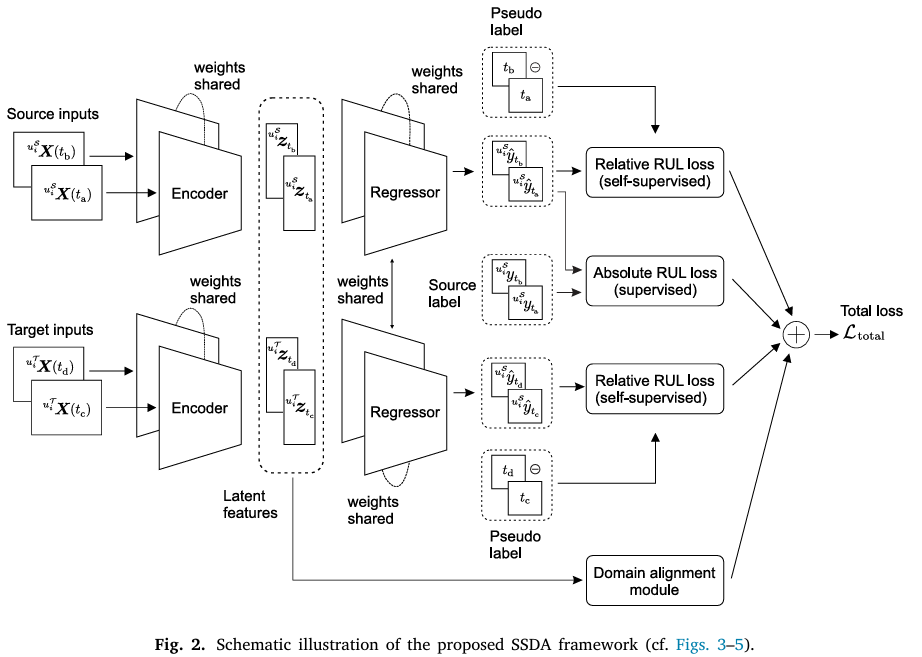

In [8]:
def build_pair_index(data):
    """每次训练前建立索引，避免每个样本反复扫描所有窗口。"""
    index = {}
    for unit in np.unique(data['unit']):
        ids = np.flatnonzero(data['unit'] == unit)
        cycles = np.unique(data['cycle'][ids])
        if len(cycles) >= 2:
            index[int(unit)] = {int(cycle): ids[data['cycle'][ids] == cycle] for cycle in cycles}
    if not index:
        raise ValueError('同一发动机至少需要两个不同循环才能做相对 RUL 自监督')
    return index

def sample_pairs(data, batch_size, rng, index=None):
    """均匀选发动机，再选两个不同循环；不访问目标 RUL/健康真值。"""
    if index is None:
        index = build_pair_index(data)
    units = list(index)
    early, late = [], []
    for _ in range(batch_size):
        unit = int(rng.choice(units))
        first, last = np.sort(rng.choice(list(index[unit]), 2, replace=False))
        early.append(rng.choice(index[unit][int(first)]))
        late.append(rng.choice(index[unit][int(last)]))
    return np.asarray(early), np.asarray(late)

def rmse_loss(prediction, truth):
    """减去数值稳定常数，使完全一致时损失为零。"""
    return torch.sqrt(F.mse_loss(prediction, truth) + 1e-08) - 0.0001

def ssl_loss(pred_earlier, pred_later, delta_cycles, y_scale):
    return rmse_loss(pred_earlier - pred_later, delta_cycles / y_scale)

def siamese_forward(model, data, early_ids, late_ids, config):
    """两次调用同一 model：共享权重，不是初始化相同的两个独立模型。"""
    early = model(*tensors(data, early_ids, config))
    late = model(*tensors(data, late_ids, config))
    return (early, late)

def multi_kernel_mmd(source_features, target_features):
    """五个 Gaussian 核的和；含对角项的非负 biased MMD² 估计。"""
    all_features = torch.cat([source_features, target_features], dim=0)
    distance = torch.cdist(all_features, all_features).square()
    count = len(all_features)
    bandwidth = (distance.detach().sum() / max(count * (count - 1), 1)).clamp_min(1e-06)
    kernel = sum((torch.exp(-distance / (bandwidth * scale)) for scale in (0.25, 0.5, 1.0, 2.0, 4.0)))
    n = len(source_features)
    return kernel[:n, :n].mean() + kernel[n:, n:].mean() - 2 * kernel[:n, n:].mean()

## 9. 工况对齐
主线使用 MMD。打开配置开关时，额外训练 `P_phase`：相对 RUL 自监督 + 软工况对抗对齐，替代全局 MMD。
三个阶段判别器由分类概率加权；概率 detach 是本实现稳定性修改。阶段用过去高度变化率生成，区别于论文完整预处理。此处先比较替代方案，不把两个域损失直接叠加。

In [9]:
class Reverse(torch.autograd.Function):

    @staticmethod
    def forward(ctx, x, strength):
        ctx.strength = strength
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad):
        return (-ctx.strength * grad, None)

class OperationAlignment(nn.Module):

    def __init__(self):
        super().__init__()
        self.heads = nn.ModuleList([nn.Sequential(nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 1)) for _ in range(3)])

    def forward(self, zs, zt, ps, pt, ls, lt, strength, mode):
        if mode == 'hard':
            ws = F.one_hot(ps, 3).float()
            wt = F.one_hot(pt, 3).float()
        else:
            ws = torch.softmax(ls, dim=-1).detach()
            wt = torch.softmax(lt, dim=-1).detach()
        losses = []
        for (p, head) in enumerate(self.heads):
            (a, b) = (ws[:, p], wt[:, p])
            if a.sum() < 2 or b.sum() < 2:
                continue
            src = head(Reverse.apply(zs, strength)).squeeze(-1)
            tgt = head(Reverse.apply(zt, strength)).squeeze(-1)
            sl = F.binary_cross_entropy_with_logits(src, torch.zeros_like(src), reduction='none')
            tl = F.binary_cross_entropy_with_logits(tgt, torch.ones_like(tgt), reduction='none')
            losses.append(0.5 * ((sl * a).sum() / a.sum() + (tl * b).sum() / b.sum()))
        return torch.stack(losses).mean() if losses else zs.sum() * 0

## 10. 网络输入与批量预测
普通分支只接收估计 θ；构造特征后删除真实 θ 键。目标前缀从读取阶段就不加载真实 θ 或 RUL。

In [10]:
def features(d, sc, pf=None, oracle=False):
    span = np.where(sc['xmax'] - sc['xmin'] < 1e-08, 1.0, sc['xmax'] - sc['xmin'])
    h = np.zeros((len(d['x']), len(sc['active'])), dtype='float32')
    sd = np.zeros_like(h)
    if oracle:
        h = (d['theta'][:, sc['active']] - sc['theta_center']) / sc['theta_scale']
    elif pf is not None:
        h = (pf['mean'] - sc['theta_center']) / sc['theta_scale']
        sd = pf['std'] / sc['theta_scale']
    # 真实θ不传进普通训练/适应函数
    out = {k: v for (k, v) in d.items() if k != 'theta'}
    out['x'] = (2 * (d['x'] - sc['xmin']) / span - 1).astype('float32')
    out['h'] = h.astype('float32')
    out['sd'] = sd.astype('float32')
    return out

def tensors(d, ids, c):
    return tuple((torch.as_tensor(d[k][ids], dtype=torch.float32, device=c.device) for k in ['x', 'h', 'sd']))

@torch.no_grad()
def predict(model, d, c):
    model.eval()
    out = []
    phase = []
    for i in range(0, len(d['x']), c.batch):
        ids = np.arange(i, min(i + c.batch, len(d['x'])))
        (p, _, logits) = model(*tensors(d, ids, c))
        out.append(p.cpu().numpy())
        phase.append(logits.cpu().numpy())
    return (np.concatenate(out), np.concatenate(phase))

## 11. 联合训练：
$$L=L_{SL}+\alpha(L_{SSL}^{source}+L_{SSL}^{target})+\beta L_{MMD}.$$
同一步内完成源域监督、两个域的差值自监督和域对齐。源监督使用源样本对中两个窗口的 RUL；所有方法采用相同源采样、RMSE 和最大更新预算。
只用源验证 RMSE 早停和选择检查点。记录的训练损失是归一化单位，验证 RMSE 为循环单位。网络不读取目标后缀。

In [11]:
def train_stage(model, src, val, sc, c, folder, epochs, target=None, ssl=False, alignment=None):
    """source/target 两套 Siamese 调用共享 model，联合更新而非独立预训练。"""
    folder.mkdir(parents=True, exist_ok=True)
    if target is not None:
        assert not any((key in target for key in ('y', 'theta', 'hs')))
    if ssl or alignment:
        assert target is not None, '自监督域适配需要无标签目标前缀'
    domain = OperationAlignment().to(c.device)
    parameters = list(model.parameters())
    if alignment in ('hard', 'soft'):
        parameters += list(domain.parameters())
    optimizer = torch.optim.AdamW(parameters, lr=c.lr, weight_decay=0.0001)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,
        factor=0.5,
        patience=3,
        min_lr=1e-06)
    source_index = build_pair_index(src)
    target_index = build_pair_index(target) if target is not None else None
    source_rng = np.random.default_rng(c.seed)
    target_rng = np.random.default_rng(c.seed + 77)
    (best_rmse, bad_epochs, best_epoch) = (float('inf'), 0, 0)
    history = []
    started = time.perf_counter()
    if c.device.startswith('cuda'):
        torch.cuda.reset_peak_memory_stats()
    for epoch in range(1, epochs + 1):
        model.train()
        domain.train()
        losses = []
        for step in range(c.steps_per_epoch):
            # 两个源窗口都提供监督标签；它们来自同一发动机。
            (source_early, source_late) = sample_pairs(src, c.batch, source_rng, source_index)
            (output_a, output_b) = siamese_forward(model, src, source_early, source_late, c)
            (pred_a, latent_a, phase_a) = output_a
            (pred_b, latent_b, phase_b) = output_b
            source_ids = np.concatenate([source_early, source_late])
            prediction = torch.cat([pred_a, pred_b])
            truth = torch.as_tensor(src['y'][source_ids] / sc['y_scale'],
                dtype=torch.float32,
                device=c.device)
            supervised = rmse_loss(prediction, truth)
            temporal = prediction.sum() * 0
            adaptation = prediction.sum() * 0
            phase_loss = prediction.sum() * 0
            if ssl or alignment:
                (target_early, target_late) = sample_pairs(target, c.batch, target_rng, target_index)
                (output_c, output_d) = siamese_forward(model, target, target_early, target_late, c)
                (pred_c, latent_c, phase_c) = output_c
                (pred_d, latent_d, phase_d) = output_d
                if ssl:
                    source_delta = torch.as_tensor(src['cycle'][source_late] - src['cycle'][source_early],
                        dtype=torch.float32,
                        device=c.device)
                    target_delta = torch.as_tensor(target['cycle'][target_late] - target['cycle'][target_early],
                        dtype=torch.float32,
                        device=c.device)
                    temporal = ssl_loss(pred_a, pred_b, source_delta, sc['y_scale'])
                    temporal = temporal + ssl_loss(pred_c, pred_d, target_delta, sc['y_scale'])
                source_latent = torch.cat([latent_a, latent_b])
                target_latent = torch.cat([latent_c, latent_d])
                if alignment == 'mmd':
                    adaptation = multi_kernel_mmd(source_latent, target_latent)
                elif alignment in ('hard', 'soft'):
                    target_ids = np.concatenate([target_early, target_late])
                    source_phase = torch.as_tensor(src['phase'][source_ids], device=c.device)
                    target_phase = torch.as_tensor(target['phase'][target_ids], device=c.device)
                    source_logits = torch.cat([phase_a, phase_b])
                    target_logits = torch.cat([phase_c, phase_d])
                    progress = (epoch - 1 + step / c.steps_per_epoch) / epochs
                    strength = 2 / (1 + math.exp(-10 * progress)) - 1
                    adaptation = domain(source_latent,
                        target_latent,
                        source_phase,
                        target_phase,
                        source_logits,
                        target_logits,
                        strength,
                        alignment)
                    if alignment == 'soft':
                        phase_loss = 0.5 * (F.cross_entropy(source_logits, source_phase) + F.cross_entropy(target_logits, target_phase))
            total = supervised + c.ssl_weight * temporal + c.domain_weight * adaptation + c.phase_weight * phase_loss
            if not torch.isfinite(total):
                raise FloatingPointError('出现非有限损失，请检查输入和学习率')
            optimizer.zero_grad(set_to_none=True)
            total.backward()
            nn.utils.clip_grad_norm_(parameters, 1.0)
            optimizer.step()
            losses.append([supervised.item(), temporal.item(), adaptation.item(), phase_loss.item()])
        (val_prediction, _) = predict(model, val, c)
        validation_rmse = float(np.sqrt(np.mean((val_prediction * sc['y_scale'] - val['y']) ** 2)))
        scheduler.step(validation_rmse)
        averages = np.mean(losses, axis=0)
        history.append(dict(epoch=epoch, supervised=averages[0], ssl=averages[1], domain=averages[2], phase=averages[3], val_RMSE=validation_rmse, lr=optimizer.param_groups[0]['lr']))
        # 每个epoch立即写盘，长训练中断时仍保留已完成记录。
        pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
        print(f'{folder.name} | epoch={epoch:03d} | source val RMSE={validation_rmse:.4f}',
            flush=True)
        if validation_rmse < best_rmse:
            (best_rmse, best_epoch, bad_epochs) = (validation_rmse, epoch, 0)
            torch.save(model.state_dict(), folder / 'best.pt')
        else:
            bad_epochs += 1
            if bad_epochs >= c.patience:
                break
    model.load_state_dict(torch.load(folder / 'best.pt', map_location=c.device, weights_only=True))
    save_json(folder / 'training_info.json',
        dict(best_epoch=best_epoch, best_val_rmse=best_rmse, selection='source validation only', elapsed_seconds=time.perf_counter() - started, parameters=sum((p.numel() for p in model.parameters())), gpu_peak_bytes=int(torch.cuda.max_memory_allocated()) if c.device.startswith('cuda') else None))
    return model.cpu()

## 12. 评估函数定义
这里只定义函数，不读取测试标签。所有检查点锁定以后再执行评估。整体分数按窗口统计，轨迹图按循环平均；两者不可混称。

In [12]:
def score_metrics(p, y):
    e = np.asarray(p, dtype='float64') - np.asarray(y, dtype='float64')
    with np.errstate(over='ignore'):
        score = np.expm1(np.where(e < 0, -e / 13, e / 10))
    return dict(RMSE=float(np.sqrt(np.mean(e * e))),
        MAE=float(np.mean(abs(e))),
        NASA_score_sum=float(score.sum()),
        NASA_score_mean=float(score.mean()))

def evaluate_saved(models, test, truth, sc, c, root, pf):
    rows = []
    grouped = []
    for (name, model) in models.items():
        model.to(c.device)
        data = features(test,
            sc,
            oracle=True) if name == 'O_oracle' else features(test,
            sc,
            pf=pf if name.startswith('P_') else None)
        (p, logits) = predict(model, data, c)
        p = p * sc['y_scale']
        frame = pd.DataFrame({k: test[k] for k in ['unit', 'cycle', 'row', 'phase']})
        frame['true'] = truth
        frame['prediction'] = p
        frame.to_csv(root / name / 'predictions.csv', index=False)
        model.cpu()
        rows.append(dict(method=name, seed=c.seed, unit=c.target, n=len(p), **score_metrics(p, truth)))
        for ph in np.unique(test['phase']):
            m = test['phase'] == ph
            grouped.append(dict(method=name, group=f'phase_{ph}', n=int(m.sum()), **score_metrics(p[m], truth[m])))
        # 寿命归一化进度仅用于事后报告；绝不用于输入、配对或训练选择。
        progress = test['cycle'] / (test['cycle'] + truth)
        for (stage, a, b) in [('early', 0, 1 / 3), ('middle', 1 / 3, 2 / 3), ('late', 2 / 3, 1.01)]:
            m = (progress >= a) & (progress < b)
            if m.any():
                grouped.append(dict(method=name, group=stage, n=int(m.sum()), **score_metrics(p[m], truth[m])))
    pd.DataFrame(rows).to_csv(root / 'comparison.csv', index=False)
    pd.DataFrame(grouped).to_csv(root / 'group_metrics.csv', index=False)
    health = []
    for (j, k) in enumerate(sc['active']):
        error = pf['mean'][:, j] - test['theta'][:, k]
        health.append(dict(theta_index=int(k), RMSE=float(np.sqrt(np.mean(error ** 2))), MAE=float(np.mean(abs(error))), mean_posterior_sd=float(pf['std'][:, j].mean())))
    pd.DataFrame(health).to_csv(root / 'health_recovery.csv', index=False)
    return pd.DataFrame(rows)

## 13. 建立本次实验目录，读取训练/验证和无标签前缀
从此单元开始读取本地 H5。只打印实际读取的信息，不预置数据规模结论。
不读取目标后缀。验证健康真值仅供 oracle；普通分支通过 observable() 隔离。

In [13]:
seed_all(c.seed)
start = time.perf_counter()
root = RESULT_BASE / f"{c.mode}_seed{c.seed}_{time.strftime('%Y%m%d_%H%M%S')}_{time.time_ns() % 1000000}"
root.mkdir(parents=True, exist_ok=True)
save_json(root / 'config.json', asdict(c))
print('OUTPUT:', root.resolve(), flush=True)
source = load_windows(c, 'dev', c.train_units, True, True)
# theta只供oracle和最终验证诊断
validation = load_windows(c, 'dev', c.val_units, True, True)
prefix = load_windows(c, 'test', [c.target], region='prefix')
assert set(source['unit']).isdisjoint(set(validation['unit']))
assert c.target not in set(source['unit']) | set(validation['unit'])
assert prefix['cycle'].max() <= c.prefix_cycles and 'y' not in prefix and ('theta' not in prefix)
for u in c.train_units:
    mask = source['unit'] == u
    if np.ptp(source['y'][mask] + source['cycle'][mask]) > 1e-05:
        raise ValueError('Y+cycle不是常数，不能使用当前时序自监督公式')
sc = fit_scales(source)
with h5py.File(c.data, 'r') as f:
    health_names = names(f, 'T_var')
    sensor_names = names(f, 'X_s_var')
manifest = dict(data=data_fingerprint(c.data),
    train=list(c.train_units),
    val=list(c.val_units),
    target=c.target,
    prefix_cycles=c.prefix_cycles,
    active_health=[health_names[i] for i in sc['active']],
    removed_observations=[dict(removed=sensor_names[j], reference=sensor_names[k], relative_residual=r) for (j, k, r) in sc['dropped']],
    observation_channels=[sensor_names[i] for i in sc['obs_idx']],
    protocol='cycle-local 50-row windows; sparse equally spaced endpoints; no historical dense-score ranking',
    selection='source validation only; all checkpoints locked before target suffix read',
    y_scale=sc['y_scale'],
    versions=dict(torch=torch.__version__, numpy=np.__version__, python=platform.python_version()))
save_json(root / 'manifest.json', manifest)
print('active theta:',
    manifest['active_health'],
    'redundant:',
    manifest['removed_observations'],
    flush=True)
models = {}
print('源训练窗口:', len(source['x']), '源验证窗口:', len(validation['x']), '目标无标签前缀窗口:', len(prefix['x']))
display(pd.DataFrame({'source_unit': source['unit'], 'cycle': source['cycle']}).groupby('source_unit').agg(['min', 'max', 'count']))

OUTPUT: C:\Users\Alina\AppData\Local\Temp\81a54e54-1de1-4ca6-98df-69af2d085b5b_PCM_SSDA_Full_Pipeline.zip.b5b\PCM_SSDA_full_results\train_seed42_20260927_173937_461100
active theta: ['HPT_eff_mod', 'LPT_eff_mod', 'LPT_flow_mod'] redundant: [{'removed': 'P21', 'reference': 'P15', 'relative_residual': 1.685604643623981e-07}]
源训练窗口: 4560 源验证窗口: 792 目标无标签前缀窗口: 240


cycle          
              min max count
source_unit                
2               1  75   900
5               1  89  1068
10              1  82   984
16              1  63   756
18              1  71   852

## 14. 运行 PCM 校准并缓存
依次训练留一发动机代理、拟合观测误差、推断源/验证/目标前缀的健康状态。这一步可能较慢；PF 不反向传播进代理或 Transformer。

In [14]:
print('[PCM] 1/3 开始拟合前向代理与观测误差', flush=True)
(pack, folds) = fit_calibrator(source, sc, c, root)
print('[PCM] 2/3 开始逐源发动机滤波', flush=True)
pf_source = calibrate_source(source, folds, c)
print('[PCM] 3/3 过滤源验证与目标无标签前缀', flush=True)
(pf_val, _) = particle_filter(observable(validation), pack, c)
(pf_prefix, prefix_state) = particle_filter(prefix, pack, c)
torch.save(prefix_state, root / 'pf_prefix_state.pt')
for (n, d, pf) in [('source', source, pf_source), ('validation', validation, pf_val), ('prefix', prefix, pf_prefix)]:
    np.savez_compressed(root / f'pf_{n}.npz', **pf, unit=d['unit'], cycle=d['cycle'], row=d['row'])
src = features(source, sc, pf_source)
va = features(validation, sc, pf_val)
tar = features(prefix, sc, pf_prefix)
sraw = features(source, sc)
vraw = features(validation, sc)
soracle = features(source, sc, oracle=True)
voracle = features(validation, sc, oracle=True)
raw_target = features(prefix, sc)
print('PCM完成。结果已缓存到:', root)

[PCM] 1/3 开始拟合前向代理与观测误差
[代理训练] proxy_without_U2 | epoch 1/60 | MSE=0.894618
[代理训练] proxy_without_U2 | epoch 2/60 | MSE=0.648824
[代理训练] proxy_without_U2 | epoch 3/60 | MSE=0.325740
[代理训练] proxy_without_U2 | epoch 4/60 | MSE=0.074438
[代理训练] proxy_without_U2 | epoch 5/60 | MSE=0.019461
[代理训练] proxy_without_U2 | epoch 6/60 | MSE=0.010691
[代理训练] proxy_without_U2 | epoch 7/60 | MSE=0.008030
[代理训练] proxy_without_U2 | epoch 8/60 | MSE=0.006498
[代理训练] proxy_without_U2 | epoch 9/60 | MSE=0.005556
[代理训练] proxy_without_U2 | epoch 10/60 | MSE=0.004829
[代理训练] proxy_without_U2 | epoch 11/60 | MSE=0.004231
[代理训练] proxy_without_U2 | epoch 12/60 | MSE=0.003730
[代理训练] proxy_without_U2 | epoch 13/60 | MSE=0.003314
[代理训练] proxy_without_U2 | epoch 14/60 | MSE=0.002960
[代理训练] proxy_without_U2 | epoch 15/60 | MSE=0.002659
[代理训练] proxy_without_U2 | epoch 16/60 | MSE=0.002407
[代理训练] proxy_without_U2 | epoch 17/60 | MSE=0.002193
[代理训练] proxy_without_U2 | epoch 18/60 | MSE=0.002006
[代理训练] proxy_without_U2 | epoch

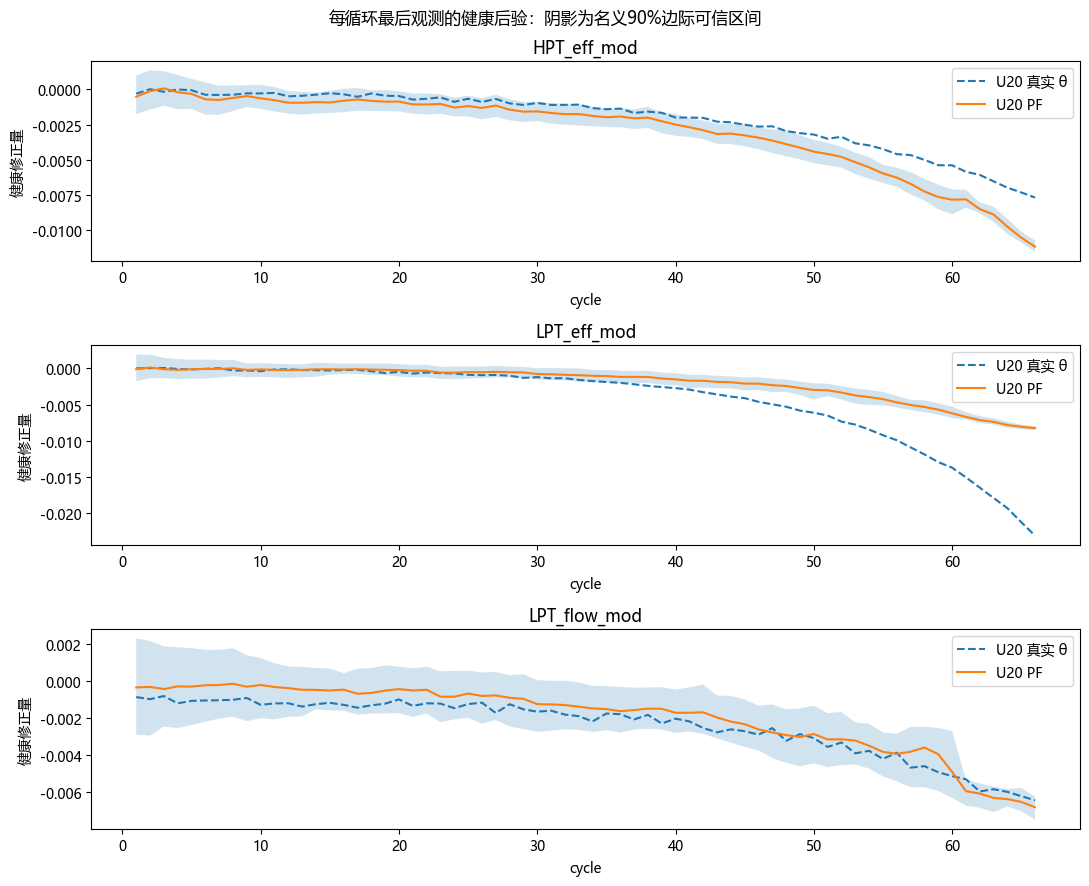

,unit,parameter,n,RMSE,MAE,mean_ESS_fraction,max_boundary_mass
0,20,HPT_eff_mod,792,0.001187,0.000929,0.751429,0.0
1,20,LPT_eff_mod,792,0.004253,0.002449,0.751429,0.0
2,20,LPT_flow_mod,792,0.000580,0.000529,0.751429,0.0


,unit,parameter,nominal,empirical,mean_width
0,20,HPT_eff_mod,0.50,0.148990,0.000678
1,20,HPT_eff_mod,0.80,0.438131,0.001303
2,20,HPT_eff_mod,0.90,0.638889,0.001680
3,20,HPT_eff_mod,0.95,0.734848,0.002009
4,20,LPT_eff_mod,0.50,0.343434,0.000754
5,20,LPT_eff_mod,0.80,0.469697,0.001414
6,20,LPT_eff_mod,0.90,0.531566,0.001840
7,20,LPT_eff_mod,0.95,0.568182,0.002209
8,20,LPT_flow_mod,0.50,0.501263,0.001134
9,20,LPT_flow_mod,0.80,0.977273,0.002183


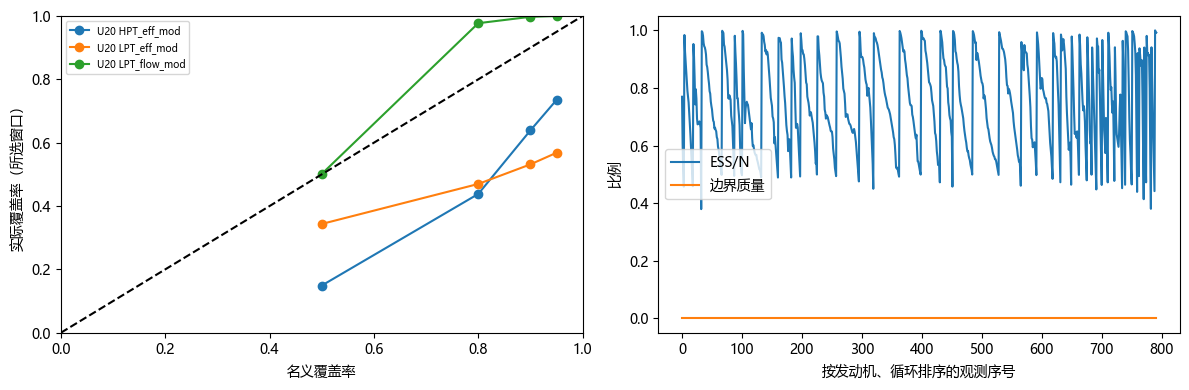

,unit,cycle,row,smallest_singular,largest_singular,condition_number
count,48.0,48.00000,4.800000e+01,48.000000,48.000000,48.000000
mean,20.0,33.50000,4.882037e+06,1.107865,10.726023,10.190164
std,0.0,19.58723,2.263710e+05,0.248359,1.632920,2.883467
min,20.0,1.00000,4.495336e+06,0.648898,7.579601,5.335725
25%,20.0,16.75000,4.693798e+06,0.923541,9.030464,8.183594
50%,20.0,33.50000,4.878734e+06,1.069817,11.534008,10.114609
75%,20.0,50.25000,5.072406e+06,1.295139,11.889096,11.847801
max,20.0,66.00000,5.263446e+06,1.549734,12.699571,19.570980


较小的最小奇异值提示某些健康方向影响弱；结果也可能反映代理模型本身不足。


,sensor,standardized_RMSE,standardized_bias
0,T24,0.023449,-0.008611
1,T30,0.017759,0.001402
2,T48,0.021455,-0.006513
3,T50,0.031042,0.005735
4,P15,0.022451,-0.009193
5,P2,0.015374,-0.000793
6,P24,0.027233,-0.006629
7,Ps30,0.011674,-0.001857
8,P40,0.011914,0.000651
9,P50,0.013597,-0.002853


上述指标只使用源验证 U20，目标健康真值未读取。


In [15]:
def calibration_diagnostics(data, posterior, parameter_names, scales, config, folder):
    """只作事后评估，不更新代理、先验、滤波状态或神经网络。"""
    folder.mkdir(exist_ok=True, parents=True)
    levels = [(0.50, 'q25', 'q75'), (0.80, 'q10', 'q90'),
              (0.90, 'q05', 'q95'), (0.95, 'q025', 'q975')]
    truth = data['theta'][:, scales['active']]
    rows, coverage = [], []
    fig, axes = plt.subplots(len(parameter_names), 1,
                             figsize=(11, 3*len(parameter_names)), squeeze=False)
    # 分发动机、分参数报告，防止长轨迹掩盖短轨迹。
    for unit in np.unique(data['unit']):
        mask = data['unit'] == unit
        for j, name in enumerate(parameter_names):
            error = posterior['mean'][mask, j] - truth[mask, j]
            rows.append(dict(unit=int(unit), parameter=name, n=int(mask.sum()),
                             RMSE=float(np.sqrt(np.mean(error**2))),
                             MAE=float(np.mean(np.abs(error))),
                             mean_ESS_fraction=float(np.mean(posterior['ess'][mask]/config.particles)),
                             max_boundary_mass=float(posterior['boundary_mass'][mask].max())))
            for nominal, lower_key, upper_key in levels:
                lower, upper = posterior[lower_key][mask, j], posterior[upper_key][mask, j]
                coverage.append(dict(unit=int(unit), parameter=name, nominal=nominal,
                                     empirical=float(np.mean((truth[mask,j]>=lower)&(truth[mask,j]<=upper))),
                                     mean_width=float(np.mean(upper-lower))))
            frame = pd.DataFrame({'cycle': data['cycle'][mask], 'truth': truth[mask,j],
                                  'mean': posterior['mean'][mask,j],
                                  'lower': posterior['q05'][mask,j], 'upper': posterior['q95'][mask,j]}).groupby('cycle').last()
            axes[j,0].plot(frame.index, frame['truth'], '--', label=f'U{unit} 真实 θ')
            axes[j,0].plot(frame.index, frame['mean'], label=f'U{unit} PF')
            axes[j,0].fill_between(frame.index, frame['lower'], frame['upper'], alpha=0.2)
            axes[j,0].set(title=name, xlabel='cycle', ylabel='健康修正量')
            axes[j,0].legend()
    fig.suptitle('每循环最后观测的健康后验：阴影为名义90%边际可信区间')
    fig.tight_layout()
    fig.savefig(folder / 'health_posterior.png', dpi=160, bbox_inches='tight')
    plt.show()
    metrics, coverage = pd.DataFrame(rows), pd.DataFrame(coverage)
    metrics.to_csv(folder / 'theta_metrics.csv', index=False)
    coverage.to_csv(folder / 'posterior_coverage.csv', index=False)
    display(metrics)
    display(coverage)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for (unit, name), frame in coverage.groupby(['unit', 'parameter']):
        axes[0].plot(frame['nominal'], frame['empirical'], 'o-', label=f'U{unit} {name}')
    axes[0].plot([0,1], [0,1], 'k--')
    axes[0].set(xlabel='名义覆盖率', ylabel='实际覆盖率（所选窗口）', xlim=(0,1), ylim=(0,1))
    axes[0].legend(fontsize=7)
    axes[1].plot(posterior['ess']/config.particles, label='ESS/N')
    axes[1].plot(posterior['boundary_mass'], label='边界质量')
    axes[1].set(xlabel='按发动机、循环排序的观测序号', ylabel='比例')
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(folder / 'coverage_ess.png', dpi=160, bbox_inches='tight')
    plt.show()
    return metrics, coverage

def local_identifiability(data, posterior, pack, config, folder, max_points=48):
    """标准化 θ 到白化观测响应的局部 Jacobian；不作全局可辨识保证。"""
    scales = pack['scales']
    proxy = pack['model']
    proxy.eval()
    records = []
    for index in np.linspace(0, len(data['x'])-1, min(max_points, len(data['x']))).astype(int):
        observation = (data['x'][index,-1]-scales['raw_mean'])/scales['raw_std']
        condition = torch.tensor(observation[:4], dtype=torch.float32, device=config.device)
        estimate = (posterior['mean'][index]-scales['theta_center'])/scales['theta_scale']
        estimate = torch.tensor(estimate, dtype=torch.float32, device=config.device, requires_grad=True)
        jacobian = torch.autograd.functional.jacobian(
            lambda state: proxy(condition[None], state[None]).squeeze(0), estimate)
        covariance = pack['cov'][int(data['phase'][index])]
        whitened = np.linalg.solve(np.linalg.cholesky(covariance), jacobian.detach().cpu().numpy())
        singular = np.linalg.svd(whitened, compute_uv=False)
        condition_number = float(singular[0]/singular[-1]) if singular[-1]>1e-12 else float('inf')
        records.append(dict(unit=int(data['unit'][index]), cycle=int(data['cycle'][index]),
                            row=int(data['row'][index]), smallest_singular=float(singular[-1]),
                            largest_singular=float(singular[0]), condition_number=condition_number))
    report = pd.DataFrame(records)
    report.to_csv(folder / 'local_jacobian.csv', index=False)
    display(report.describe())
    print('较小的最小奇异值提示某些健康方向影响弱；结果也可能反映代理模型本身不足。')
    return report

diagnostic_folder = root / 'calibration_validation'
theta_metrics, posterior_coverage = calibration_diagnostics(
    validation, pf_val, manifest['active_health'], sc, c, diagnostic_folder)
jacobian_report = local_identifiability(observable(validation), pf_val, pack, c, diagnostic_folder)
proxy_errors = proxy_residual(pack['model'], validation, sc, c)
proxy_report = pd.DataFrame({'sensor': manifest['observation_channels'],
                             'standardized_RMSE': np.sqrt(np.mean(proxy_errors**2, axis=0)),
                             'standardized_bias': proxy_errors.mean(axis=0)})
proxy_report.to_csv(diagnostic_folder / 'proxy_validation_error.csv', index=False)
display(proxy_report)
print('上述指标只使用源验证 U20，目标健康真值未读取。')


## 15. 独立模型训练
下面各方法都从固定种子重新初始化，联合训练预算相同。`quick` 仅检查流程，不能用于性能结论。
B0 保留基线架构，但共同训练协议改为 RMSE 和配对采样；因此是本协议重训基线，不是历史分数复现。
不要在看过目标后缀分数后继续调参并把同一后缀当作独立测试集。

In [16]:
def fit_arm(name, training, valid, enhanced, health, target=None, ssl=False, alignment=None):
    """各消融只改变声明的模块，记录训练历史与源验证最佳检查点。"""
    print(f'\n[开始训练] {name} | 最多 {c.joint_epochs} 轮 | 每轮 {c.steps_per_epoch} 步', flush=True)
    seed_all(c.seed)
    model = HealthTransformer(c.window,
        len(sc['active']),
        enhanced=enhanced,
        use_health=health).to(c.device)
    models[name] = train_stage(model,
        training,
        valid,
        sc,
        c,
        root / name,
        c.joint_epochs,
        target=target,
        ssl=ssl,
        alignment=alignment)
    info = json.loads((root / name / 'training_info.json').read_text(encoding='utf-8'))
    display(pd.DataFrame([dict(method=name, **info)]))

### 15.1 原始 Transformer 架构

In [17]:
fit_arm('B0_raw', sraw, vraw, False, False)


[开始训练] B0_raw | 最多 110 轮 | 每轮 80 步


e:\RUL\venv\lib\site-packages\torch\nn\modules\transformer.py:382: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


B0_raw | epoch=001 | source val RMSE=18.4404
B0_raw | epoch=002 | source val RMSE=17.6070
B0_raw | epoch=003 | source val RMSE=16.6817
B0_raw | epoch=004 | source val RMSE=13.0393
B0_raw | epoch=005 | source val RMSE=11.4651
B0_raw | epoch=006 | source val RMSE=11.9248
B0_raw | epoch=007 | source val RMSE=8.2469
B0_raw | epoch=008 | source val RMSE=7.7741
B0_raw | epoch=009 | source val RMSE=7.8343
B0_raw | epoch=010 | source val RMSE=10.1362
B0_raw | epoch=011 | source val RMSE=10.2271
B0_raw | epoch=012 | source val RMSE=6.3877
B0_raw | epoch=013 | source val RMSE=7.9022
B0_raw | epoch=014 | source val RMSE=8.3748
B0_raw | epoch=015 | source val RMSE=10.3162
B0_raw | epoch=016 | source val RMSE=9.0401
B0_raw | epoch=017 | source val RMSE=8.2766
B0_raw | epoch=018 | source val RMSE=8.4311
B0_raw | epoch=019 | source val RMSE=10.1001
B0_raw | epoch=020 | source val RMSE=7.2829
B0_raw | epoch=021 | source val RMSE=8.9728
B0_raw | epoch=022 | source val RMSE=10.6445
B0_raw | epoch=023 | 

,method,best_epoch,best_val_rmse,selection,elapsed_seconds,parameters,gpu_peak_bytes
0,B0_raw,12,6.387654,source validation only,160.6826,23332,74653184


### 15.2 增强 Transformer：隔离网络结构收益

In [18]:
fit_arm('A1_enhanced_raw', sraw, vraw, True, False)


[开始训练] A1_enhanced_raw | 最多 110 轮 | 每轮 80 步


e:\RUL\venv\lib\site-packages\torch\nn\modules\transformer.py:382: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


A1_enhanced_raw | epoch=001 | source val RMSE=17.4858
A1_enhanced_raw | epoch=002 | source val RMSE=12.7597
A1_enhanced_raw | epoch=003 | source val RMSE=12.7726
A1_enhanced_raw | epoch=004 | source val RMSE=11.9332
A1_enhanced_raw | epoch=005 | source val RMSE=10.5199
A1_enhanced_raw | epoch=006 | source val RMSE=8.5014
A1_enhanced_raw | epoch=007 | source val RMSE=8.0840
A1_enhanced_raw | epoch=008 | source val RMSE=10.6198
A1_enhanced_raw | epoch=009 | source val RMSE=9.8117
A1_enhanced_raw | epoch=010 | source val RMSE=10.6831
A1_enhanced_raw | epoch=011 | source val RMSE=7.7268
A1_enhanced_raw | epoch=012 | source val RMSE=11.3616
A1_enhanced_raw | epoch=013 | source val RMSE=10.1301
A1_enhanced_raw | epoch=014 | source val RMSE=10.0876
A1_enhanced_raw | epoch=015 | source val RMSE=13.0730
A1_enhanced_raw | epoch=016 | source val RMSE=12.7709
A1_enhanced_raw | epoch=017 | source val RMSE=12.1389
A1_enhanced_raw | epoch=018 | source val RMSE=10.3028
A1_enhanced_raw | epoch=019 | so

,method,best_epoch,best_val_rmse,selection,elapsed_seconds,parameters,gpu_peak_bytes
0,A1_enhanced_raw,11,7.726791,source validation only,187.830321,23814,81034240


### 15.3 Oracle：真实健康参数对照

In [19]:
fit_arm('O_oracle', soracle, voracle, True, True)


[开始训练] O_oracle | 最多 110 轮 | 每轮 80 步


e:\RUL\venv\lib\site-packages\torch\nn\modules\transformer.py:382: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


O_oracle | epoch=001 | source val RMSE=14.0360
O_oracle | epoch=002 | source val RMSE=9.3298
O_oracle | epoch=003 | source val RMSE=9.3725
O_oracle | epoch=004 | source val RMSE=9.2930
O_oracle | epoch=005 | source val RMSE=8.2708
O_oracle | epoch=006 | source val RMSE=7.0265
O_oracle | epoch=007 | source val RMSE=5.9918
O_oracle | epoch=008 | source val RMSE=5.6746
O_oracle | epoch=009 | source val RMSE=5.6877
O_oracle | epoch=010 | source val RMSE=7.7292
O_oracle | epoch=011 | source val RMSE=6.2106
O_oracle | epoch=012 | source val RMSE=5.9890
O_oracle | epoch=013 | source val RMSE=6.5568
O_oracle | epoch=014 | source val RMSE=6.6397
O_oracle | epoch=015 | source val RMSE=5.9713
O_oracle | epoch=016 | source val RMSE=6.9103
O_oracle | epoch=017 | source val RMSE=6.8807
O_oracle | epoch=018 | source val RMSE=5.9501
O_oracle | epoch=019 | source val RMSE=6.7122
O_oracle | epoch=020 | source val RMSE=6.7863


,method,best_epoch,best_val_rmse,selection,elapsed_seconds,parameters,gpu_peak_bytes
0,O_oracle,8,5.674605,source validation only,141.516716,23814,81379840


### 15.4 增强 Transformer + PCM：隔离校准收益

In [20]:
fit_arm('P_pf', src, va, True, True)


[开始训练] P_pf | 最多 110 轮 | 每轮 80 步


e:\RUL\venv\lib\site-packages\torch\nn\modules\transformer.py:382: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


P_pf | epoch=001 | source val RMSE=15.9587
P_pf | epoch=002 | source val RMSE=11.0952
P_pf | epoch=003 | source val RMSE=10.4044
P_pf | epoch=004 | source val RMSE=10.3292
P_pf | epoch=005 | source val RMSE=9.4696
P_pf | epoch=006 | source val RMSE=8.1071
P_pf | epoch=007 | source val RMSE=7.9815
P_pf | epoch=008 | source val RMSE=7.2699
P_pf | epoch=009 | source val RMSE=7.9428
P_pf | epoch=010 | source val RMSE=10.2460
P_pf | epoch=011 | source val RMSE=10.1794
P_pf | epoch=012 | source val RMSE=11.1958
P_pf | epoch=013 | source val RMSE=8.3555
P_pf | epoch=014 | source val RMSE=7.5959
P_pf | epoch=015 | source val RMSE=10.2200
P_pf | epoch=016 | source val RMSE=9.3091
P_pf | epoch=017 | source val RMSE=9.5215
P_pf | epoch=018 | source val RMSE=9.2378
P_pf | epoch=019 | source val RMSE=9.2460
P_pf | epoch=020 | source val RMSE=9.2592


,method,best_epoch,best_val_rmse,selection,elapsed_seconds,parameters,gpu_peak_bytes
0,P_pf,8,7.269852,source validation only,134.813569,23814,81379840


### 15.5 PCM + 相对 RUL 自监督：不做域对齐

In [21]:
fit_arm('P_ssl', src, va, True, True, target=tar, ssl=True)


[开始训练] P_ssl | 最多 110 轮 | 每轮 80 步


e:\RUL\venv\lib\site-packages\torch\nn\modules\transformer.py:382: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


P_ssl | epoch=001 | source val RMSE=15.8208
P_ssl | epoch=002 | source val RMSE=10.5382
P_ssl | epoch=003 | source val RMSE=10.6279
P_ssl | epoch=004 | source val RMSE=9.5856
P_ssl | epoch=005 | source val RMSE=9.9426
P_ssl | epoch=006 | source val RMSE=8.0214
P_ssl | epoch=007 | source val RMSE=8.3862
P_ssl | epoch=008 | source val RMSE=6.8217
P_ssl | epoch=009 | source val RMSE=9.0320
P_ssl | epoch=010 | source val RMSE=8.9115
P_ssl | epoch=011 | source val RMSE=8.1705
P_ssl | epoch=012 | source val RMSE=8.2583
P_ssl | epoch=013 | source val RMSE=8.3925
P_ssl | epoch=014 | source val RMSE=10.6311
P_ssl | epoch=015 | source val RMSE=8.9368
P_ssl | epoch=016 | source val RMSE=10.1440
P_ssl | epoch=017 | source val RMSE=9.0873
P_ssl | epoch=018 | source val RMSE=9.3414
P_ssl | epoch=019 | source val RMSE=9.4558
P_ssl | epoch=020 | source val RMSE=9.2807


,method,best_epoch,best_val_rmse,selection,elapsed_seconds,parameters,gpu_peak_bytes
0,P_ssl,8,6.821738,source validation only,253.119706,23814,143119360


### 15.6 主模型：PCM + 双孪生自监督 + MMD

In [22]:
fit_arm('P_ssda', src, va, True, True, target=tar, ssl=True, alignment='mmd')


[开始训练] P_ssda | 最多 110 轮 | 每轮 80 步


e:\RUL\venv\lib\site-packages\torch\nn\modules\transformer.py:382: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


P_ssda | epoch=001 | source val RMSE=15.6530
P_ssda | epoch=002 | source val RMSE=10.4725
P_ssda | epoch=003 | source val RMSE=10.2661
P_ssda | epoch=004 | source val RMSE=9.7161
P_ssda | epoch=005 | source val RMSE=9.3261
P_ssda | epoch=006 | source val RMSE=9.0343
P_ssda | epoch=007 | source val RMSE=8.4502
P_ssda | epoch=008 | source val RMSE=6.4803
P_ssda | epoch=009 | source val RMSE=7.5935
P_ssda | epoch=010 | source val RMSE=8.4293
P_ssda | epoch=011 | source val RMSE=9.3428
P_ssda | epoch=012 | source val RMSE=7.2860
P_ssda | epoch=013 | source val RMSE=8.3145
P_ssda | epoch=014 | source val RMSE=9.8222
P_ssda | epoch=015 | source val RMSE=8.6541
P_ssda | epoch=016 | source val RMSE=9.3366
P_ssda | epoch=017 | source val RMSE=8.3971
P_ssda | epoch=018 | source val RMSE=9.0994
P_ssda | epoch=019 | source val RMSE=9.7630
P_ssda | epoch=020 | source val RMSE=9.2012


,method,best_epoch,best_val_rmse,selection,elapsed_seconds,parameters,gpu_peak_bytes
0,P_ssda,8,6.480269,source validation only,300.178157,23814,150760960


### 15.7 去掉 PCM 的 SSDA：隔离健康反演贡献

In [23]:
fit_arm('A2_ssda', sraw, vraw, True, False, target=raw_target, ssl=True, alignment='mmd')


[开始训练] A2_ssda | 最多 110 轮 | 每轮 80 步


e:\RUL\venv\lib\site-packages\torch\nn\modules\transformer.py:382: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


A2_ssda | epoch=001 | source val RMSE=17.2017
A2_ssda | epoch=002 | source val RMSE=11.8205
A2_ssda | epoch=003 | source val RMSE=10.8989
A2_ssda | epoch=004 | source val RMSE=10.6251
A2_ssda | epoch=005 | source val RMSE=9.9204
A2_ssda | epoch=006 | source val RMSE=9.8732
A2_ssda | epoch=007 | source val RMSE=10.4255
A2_ssda | epoch=008 | source val RMSE=7.7914
A2_ssda | epoch=009 | source val RMSE=8.7588
A2_ssda | epoch=010 | source val RMSE=9.0144
A2_ssda | epoch=011 | source val RMSE=7.5472
A2_ssda | epoch=012 | source val RMSE=8.7172
A2_ssda | epoch=013 | source val RMSE=8.9476
A2_ssda | epoch=014 | source val RMSE=7.5022
A2_ssda | epoch=015 | source val RMSE=9.3560
A2_ssda | epoch=016 | source val RMSE=10.4177
A2_ssda | epoch=017 | source val RMSE=9.7861
A2_ssda | epoch=018 | source val RMSE=8.4881
A2_ssda | epoch=019 | source val RMSE=10.5212
A2_ssda | epoch=020 | source val RMSE=11.9843
A2_ssda | epoch=021 | source val RMSE=10.7042
A2_ssda | epoch=022 | source val RMSE=10.5951


,method,best_epoch,best_val_rmse,selection,elapsed_seconds,parameters,gpu_peak_bytes
0,A2_ssda,14,7.502214,source validation only,420.099431,23814,149953024


### 15.8 可选：软工况对齐替代 MMD
默认跳过，先把主线比较做好。该分支不是自监督论文原始 SSDA-MMD。

In [24]:
if ENABLE_PHASE_EXTENSION:
    fit_arm('P_phase', src, va, True, True, target=tar, ssl=True, alignment='soft')
else:
    print('已跳过可选工况扩展')

已跳过可选工况扩展


## 16. 锁定检查点，再读取目标后缀做一次最终评估
只有这个阶段才加载目标 RUL 与真实健康参数。后者只用于 oracle 和健康恢复诊断；PF 只接收 observable(suffix)。

In [25]:
required = {'B0_raw', 'A1_enhanced_raw', 'O_oracle', 'P_pf', 'P_ssl', 'P_ssda', 'A2_ssda'}
assert required.issubset(models), f'请先运行训练单元：{required - set(models)}'
save_json(root / 'locked_models.json',
    {'methods': list(models), 'seed': c.seed, 'locked_before_suffix': True})
# 所有checkpoint已锁定。从这里才读取目标后缀（包括最终评估真值）。
suffix = load_windows(c, 'test', [c.target], True, True, region='suffix')
assert suffix['cycle'].min() > c.prefix_cycles
(pf_suffix, final_state) = particle_filter(observable(suffix), pack, c, prefix_state)
np.savez_compressed(root / 'pf_suffix.npz',
    **pf_suffix,
    unit=suffix['unit'],
    cycle=suffix['cycle'],
    row=suffix['row'],
    true_theta=suffix['theta'][:, sc['active']])
torch.save(final_state, root / 'pf_final_state.pt')
report = evaluate_saved(models, suffix, suffix['y'], sc, c, root, pf_suffix)
display(report)
save_json(root / 'status.json', dict(completed=True, seed=c.seed, mode=c.mode))

,method,seed,unit,n,RMSE,MAE,NASA_score_sum,NASA_score_mean
0,B0_raw,42,14,672,6.981346,5.511215,593.055438,0.882523
1,A1_enhanced_raw,42,14,672,4.912059,3.681153,345.649459,0.514359
2,O_oracle,42,14,672,3.923608,3.428925,263.817932,0.392586
3,P_pf,42,14,672,5.609976,4.492928,434.842980,0.647088
4,P_ssl,42,14,672,6.281623,5.064217,518.843277,0.772088
5,P_ssda,42,14,672,5.199191,3.923470,345.757995,0.514521
6,A2_ssda,42,14,672,5.393083,4.115529,409.458212,0.609313


## 16A. 校准是否有效：自动生成成对效果差值

优先看 **P_pf 对 A1_enhanced_raw**：增强结构一致，区别是是否输入校准健康信息。
再看 **P_ssda 对 A2_ssda**：都使用自监督和 MMD，区别是 PCM 健康分支。
不能单看 P_ssda 比 B0 好就把全部收益归给校准。

`RMSE_reduction = 参考方法RMSE − 当前方法RMSE`，正值表示下降、负值表示变差；百分比使用参考方法误差为分母。
oracle 差距是有符号差值，可能为负，不称作严格理论上限差距。单种子差值只描述这次运行，不能证明稳定优势。


,comparison,reference,candidate,reference_RMSE,candidate_RMSE,RMSE_reduction,reduction_percent,MAE_reduction
0,结构改动,B0_raw,A1_enhanced_raw,6.981346,4.912059,2.069287,29.640225,1.830062
1,校准单独贡献,A1_enhanced_raw,P_pf,4.912059,5.609976,-0.697917,-14.208227,-0.811775
2,相对 RUL 自监督贡献,P_pf,P_ssl,5.609976,6.281623,-0.671648,-11.972383,-0.571289
3,MMD 对齐贡献,P_ssl,P_ssda,6.281623,5.199191,1.082433,17.231735,1.140747
4,SSDA 中的校准贡献,A2_ssda,P_ssda,5.393083,5.199191,0.193893,3.595210,0.192059


同为增强结构、无 SSDA 的 P_pf − oracle RMSE 差距：1.6864 cycles


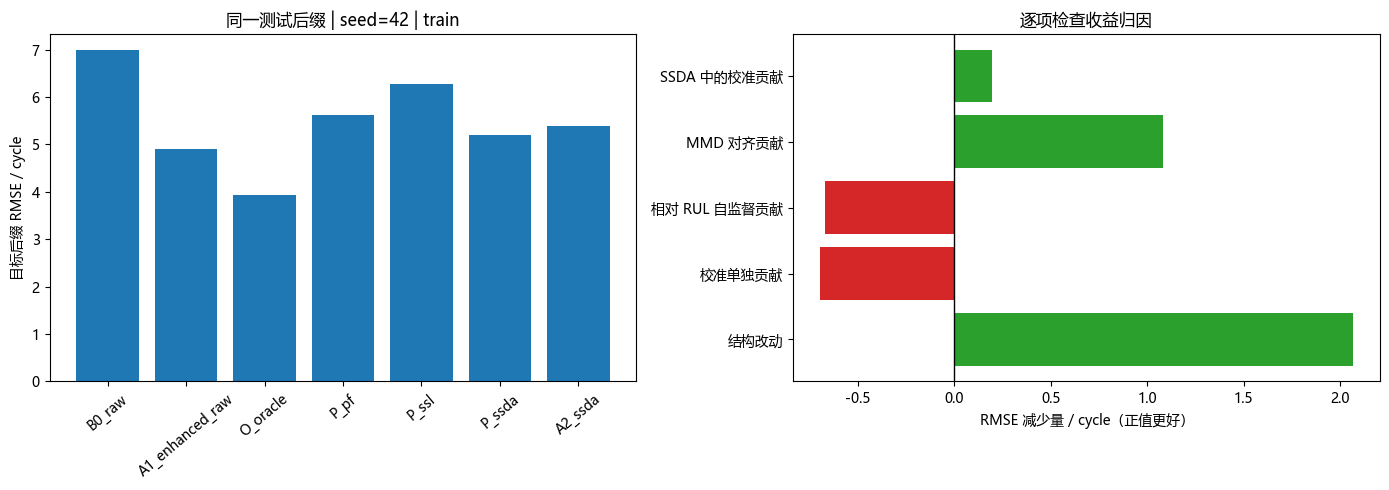

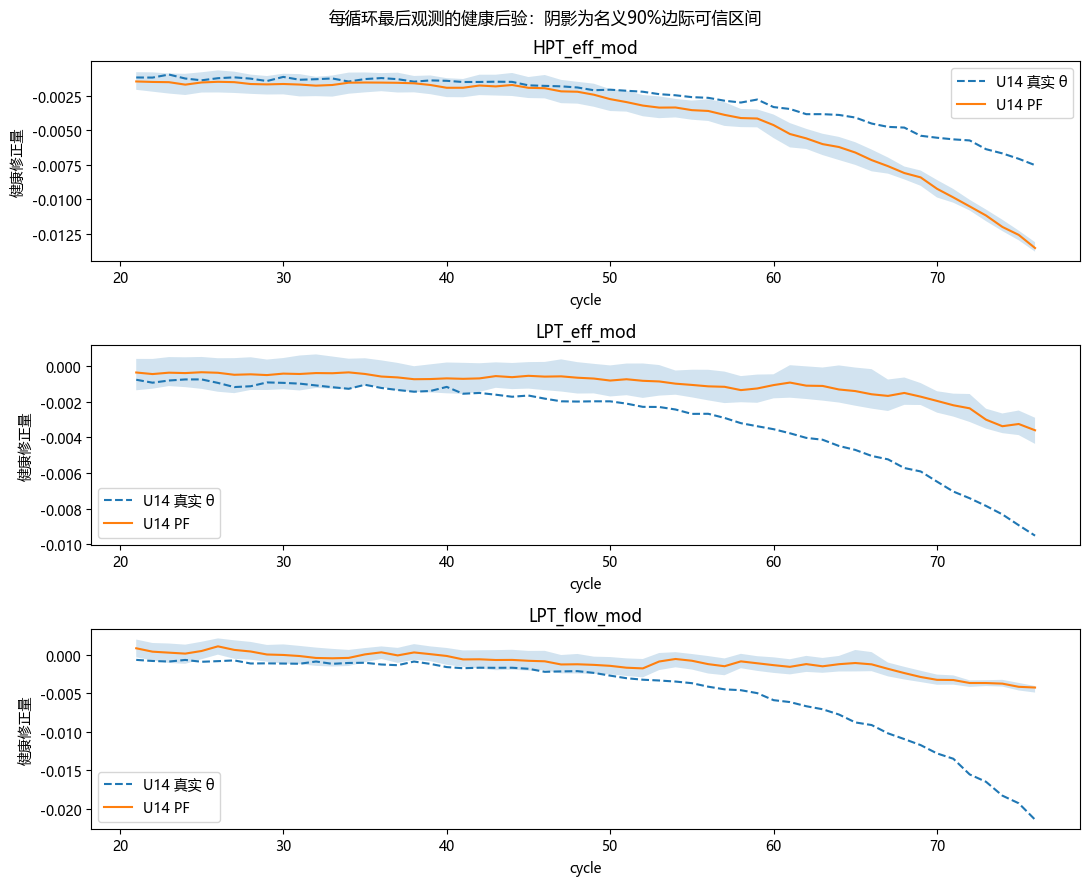

,unit,parameter,n,RMSE,MAE,mean_ESS_fraction,max_boundary_mass
0,14,HPT_eff_mod,672,0.002025,0.001364,0.733958,0.0
1,14,LPT_eff_mod,672,0.002487,0.001909,0.733958,0.0
2,14,LPT_flow_mod,672,0.005771,0.003941,0.733958,0.0


,unit,parameter,nominal,empirical,mean_width
0,14,HPT_eff_mod,0.50,0.196429,0.000618
1,14,HPT_eff_mod,0.80,0.495536,0.001162
2,14,HPT_eff_mod,0.90,0.550595,0.001489
3,14,HPT_eff_mod,0.95,0.616071,0.001773
4,14,LPT_eff_mod,0.50,0.017857,0.000679
5,14,LPT_eff_mod,0.80,0.223214,0.001336
6,14,LPT_eff_mod,0.90,0.351190,0.001702
7,14,LPT_eff_mod,0.95,0.398810,0.002011
8,14,LPT_flow_mod,0.50,0.007440,0.000866
9,14,LPT_flow_mod,0.80,0.157738,0.001687


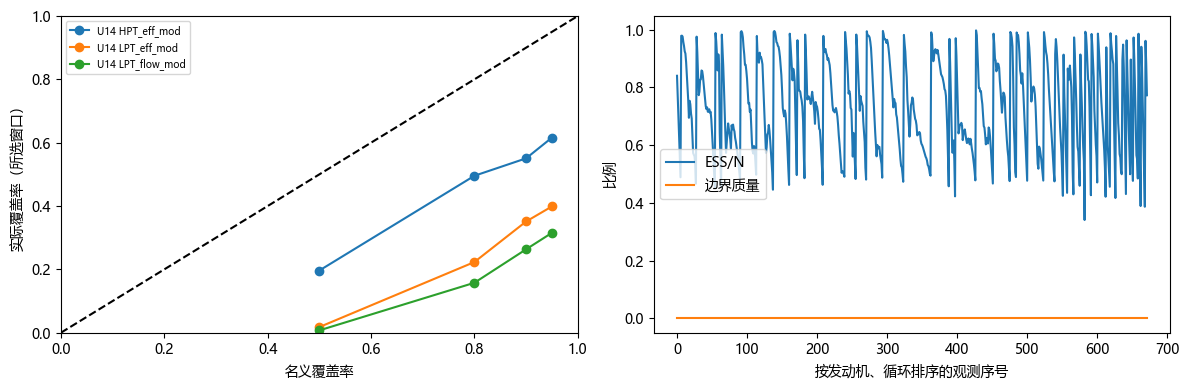

In [26]:
# 此单元只汇总锁定模型后的结果，不参与选参或模型更新。
scores = report.set_index('method')
pairs = [
    ('结构改动', 'B0_raw', 'A1_enhanced_raw'),
    ('校准单独贡献', 'A1_enhanced_raw', 'P_pf'),
    ('相对 RUL 自监督贡献', 'P_pf', 'P_ssl'),
    ('MMD 对齐贡献', 'P_ssl', 'P_ssda'),
    ('SSDA 中的校准贡献', 'A2_ssda', 'P_ssda'),
]
effects = []
for hypothesis, reference, candidate in pairs:
    base = float(scores.loc[reference, 'RMSE'])
    value = float(scores.loc[candidate, 'RMSE'])
    effects.append(dict(comparison=hypothesis, reference=reference, candidate=candidate,
                        reference_RMSE=base, candidate_RMSE=value,
                        RMSE_reduction=base-value,
                        reduction_percent=100*(base-value)/base if base>0 else np.nan,
                        MAE_reduction=float(scores.loc[reference,'MAE']-scores.loc[candidate,'MAE'])))
effects = pd.DataFrame(effects)
effects.to_csv(root / 'calibration_effects.csv', index=False, encoding='utf-8-sig')
display(effects)
oracle_gap = float(scores.loc['P_pf','RMSE']-scores.loc['O_oracle','RMSE'])
print(f'同为增强结构、无 SSDA 的 P_pf − oracle RMSE 差距：{oracle_gap:.4f} cycles')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(report['method'], report['RMSE'])
axes[0].tick_params(axis='x', rotation=40)
axes[0].set(ylabel='目标后缀 RMSE / cycle', title=f'同一测试后缀 | seed={c.seed} | {c.mode}')
colors = ['tab:green' if value>0 else 'tab:red' for value in effects['RMSE_reduction']]
axes[1].barh(effects['comparison'], effects['RMSE_reduction'], color=colors)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set(xlabel='RMSE 减少量 / cycle（正值更好）', title='逐项检查收益归因')
fig.tight_layout()
fig.savefig(root / 'calibration_effects.png', dpi=160, bbox_inches='tight')
plt.show()

# 目标健康真值仅在全部模型锁定后的诊断使用；不反馈到训练或滤波。
target_theta_metrics, target_coverage = calibration_diagnostics(
    suffix, pf_suffix, manifest['active_health'], sc, c, root / 'calibration_target_diagnostics')


## 17. 训练曲线与预测轨迹
这些图只使用本次实际输出。保存 PNG 便于组会引用；图题注明模式与种子。

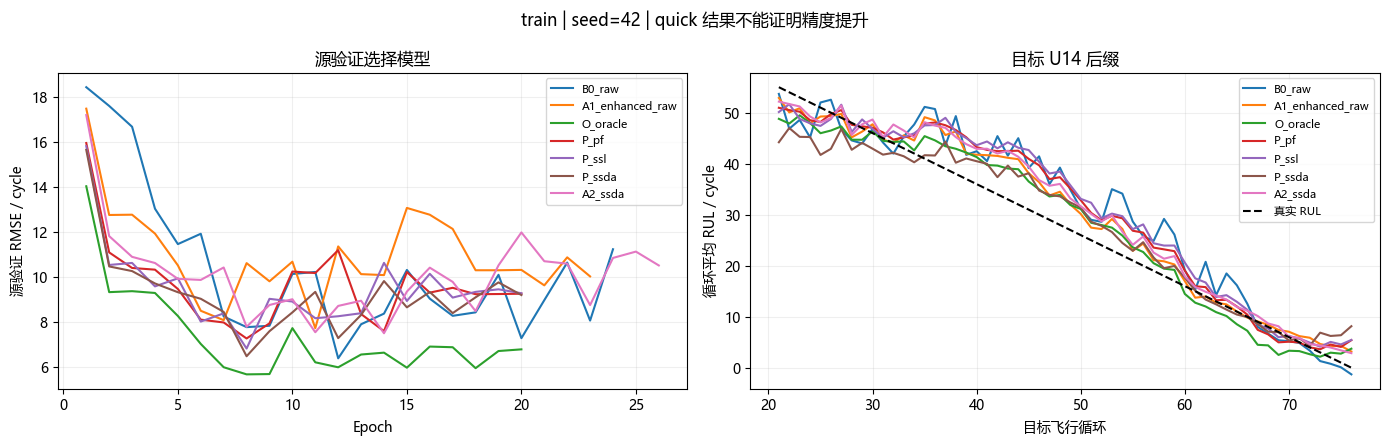

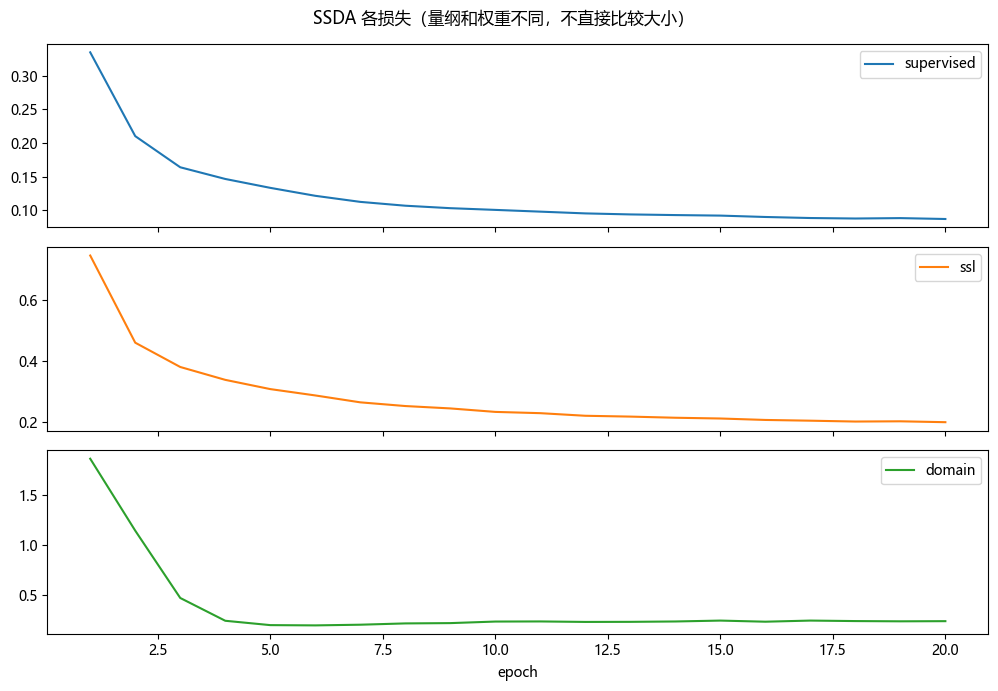

In [27]:
(fig, axes) = plt.subplots(1, 2, figsize=(14, 4.5))
for name in models:
    history = pd.read_csv(root / name / 'history.csv')
    axes[0].plot(history['epoch'], history['val_RMSE'], label=name)
    prediction = pd.read_csv(root / name / 'predictions.csv').groupby('cycle')[['true', 'prediction']].mean()
    axes[1].plot(prediction.index, prediction['prediction'], label=name)
axes[1].plot(prediction.index, prediction['true'], 'k--', label='真实 RUL')
axes[0].set(xlabel='Epoch', ylabel='源验证 RMSE / cycle', title='源验证选择模型')
axes[1].set(xlabel='目标飞行循环', ylabel='循环平均 RUL / cycle', title=f'目标 U{c.target} 后缀')
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle(f'{c.mode} | seed={c.seed} | quick 结果不能证明精度提升')
fig.tight_layout()
fig.savefig(root / 'training_and_prediction.png', dpi=160, bbox_inches='tight')
plt.show()
history = pd.read_csv(root / 'P_ssda' / 'history.csv')
history.plot(x='epoch',
    y=['supervised', 'ssl', 'domain'],
    subplots=True,
    figsize=(10, 7),
    title='SSDA 各损失（量纲和权重不同，不直接比较大小）')
plt.tight_layout()
plt.savefig(root / 'ssda_losses.png', dpi=160, bbox_inches='tight')
plt.show()

## 18. 健康反演诊断
±2σ 表示 PF 粒子后验离散程度，**未校准覆盖率**。源域代理存在工况外推或参数不可辨识时，即使拟合 Xs 较好，也不保证 θ 准确。

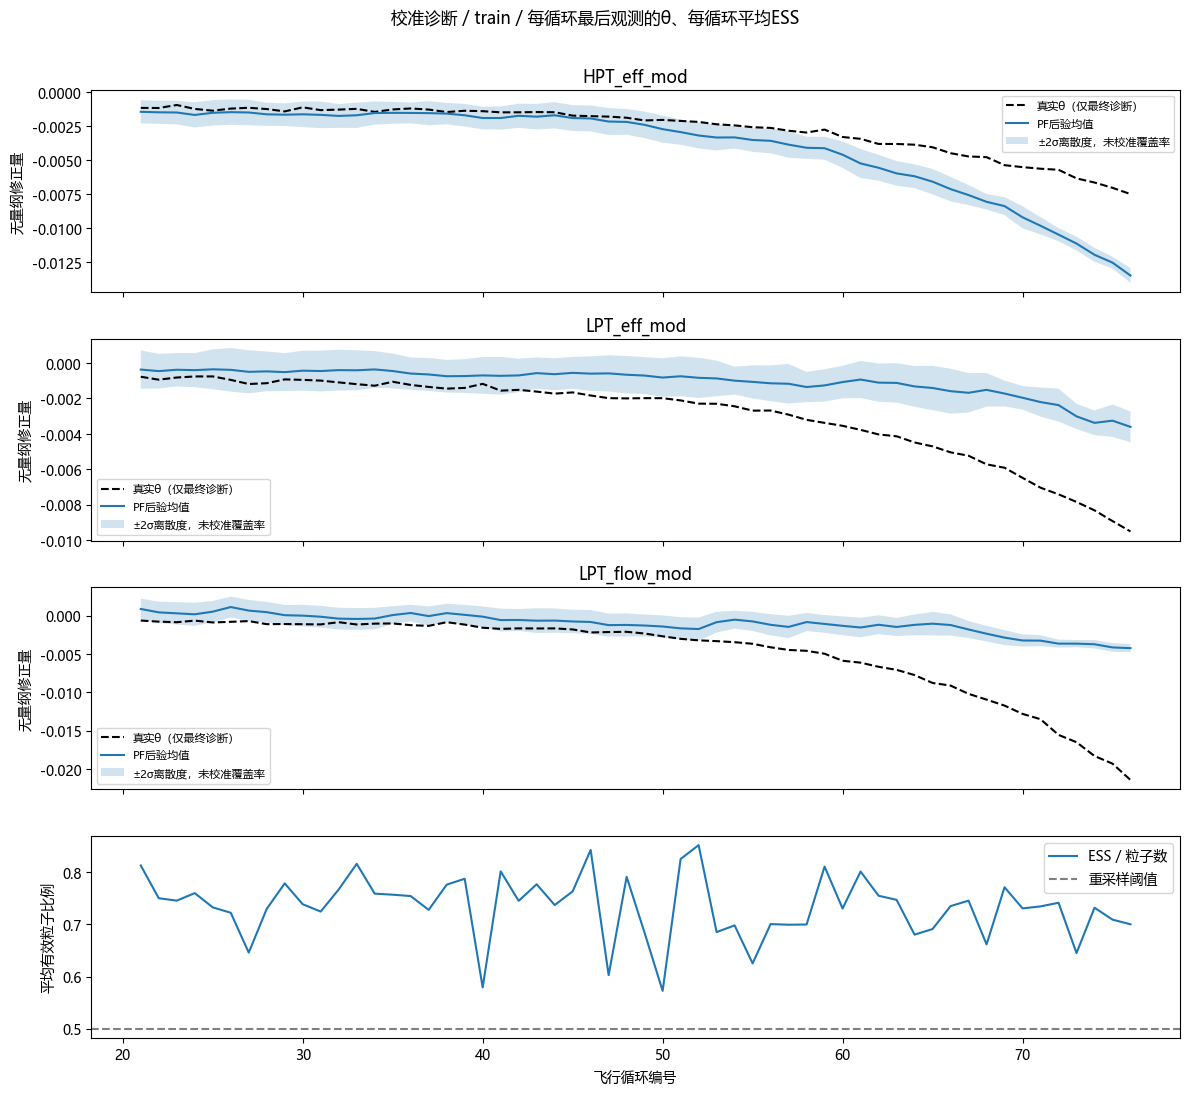

,theta_index,RMSE,MAE,mean_posterior_sd
0,6,0.002025,0.001364,0.000453
1,8,0.002487,0.001909,0.000515
2,9,0.005771,0.003941,0.000649


当前后缀最大边界质量： 0.0


In [28]:
conf = asdict(c)
pf = np.load(root / 'pf_suffix.npz')
hn = manifest['active_health']
(fig, axs) = plt.subplots(len(hn) + 1, 1, figsize=(12, 2.7 * (len(hn) + 1)), sharex=True)
for (j, n) in enumerate(hn):
    frame = pd.DataFrame({'cycle': pf['cycle'], 'true': pf['true_theta'][:, j], 'mean': pf['mean'][:, j], 'std': pf['std'][:, j]}).groupby('cycle').last()
    axs[j].plot(frame.index, frame.true, 'k--', label='真实θ（仅最终诊断）')
    axs[j].plot(frame.index, frame['mean'], label='PF后验均值')
    axs[j].fill_between(frame.index,
        frame['mean'] - 2 * frame['std'],
        frame['mean'] + 2 * frame['std'],
        alpha=0.2,
        label='±2σ离散度，未校准覆盖率')
    axs[j].set(title=n, ylabel='无量纲修正量')
    axs[j].legend(fontsize=8)
diag = pd.DataFrame({'cycle': pf['cycle'], 'ess': pf['ess'] / conf['particles']}).groupby('cycle').mean()
axs[-1].plot(diag.index, diag.ess, label='ESS / 粒子数')
axs[-1].axhline(0.5, ls='--', color='gray', label='重采样阈值')
axs[-1].set(xlabel='飞行循环编号', ylabel='平均有效粒子比例')
axs[-1].legend()
fig.suptitle(f'校准诊断 / {RUN_MODE} / 每循环最后观测的θ、每循环平均ESS', y=1.01)
fig.tight_layout()
fig.savefig(root / 'health_calibration.png', dpi=150, bbox_inches='tight')
plt.show()
display(pd.read_csv(root / 'health_recovery.csv'))
print('当前后缀最大边界质量：', float(pf['boundary_mass'].max()))